# Lab07: K Nearest Neighbors


## Types of learning

### Global Learning vs Local Learning.
Global Learning: Learning from all instances in the dataset.
- Linear Regression
- Naïve Bayes Classifier

Local Learning: Learning from some of the instances in the dataset.
- kNN

### Instance-Based Learning vs Model-Based Learning
Instance-Based Learning: Use the entire dataset as the model.
- kNN

Model-Based Learning: Use the training data to create a model that has parameters learned from the training data.
- Linear Regression
- Naïve Bayes Classifier

### Lazy Learning vs Eager Learning
Lazy vs. eager learning
- Lazy learning (e.g., instance-based learning): Simply stores training data (or only minor processing) and waits until it is given a test tuple
- Eager learning (eg. Decision trees, SVM, NN): Given a set of training set, constructs a classification model before receiving new (e.g., test) data to classify

**Lazy:** Less time in training but more time in predicting

**Accuracy**
- **Lazy method** effectively uses a richer hypothesis space since it uses many local linear functions to form its implicit global approximation to the target function
- **Eager:** must commit to a single hypothesis that covers the entire instance space


## k-Nearest Neighbors

The $k$-nearest neighbors (k-NN) algorithm is a **non-parametric** method that can be used for both classification and regression. k-NN instead stores the entire training set $\left\{ \left(\mathbf{x}^{(i)}, y^{(i)}\right) \right\}_{i=1}^{n}$ and makes predictions directly from it. The underlying assumption is that observations close to each other in the input space tend to have similar targets.

To quantify closeness, a distance function $\operatorname{dist} : \mathbb{R}^{d} \times \mathbb{R}^{d} \to \mathbb{R}_{\geq 0}$ must be chosen. The most common choice is the Euclidean distance

$$
\operatorname{dist}(\mathbf{x}, \mathbf{x}') = \left\lVert \mathbf{x} - \mathbf{x}' \right\rVert_2 = \sqrt{\sum_{j=1}^{d} \left( x_j - x'_j \right)^{2}}.
$$

Given a new input $\mathbf{x}$, let $\mathcal{N}_k(\mathbf{x}) \subseteq \{1, \ldots, n\}$ denote the indices of the $k$ training observations closest to $\mathbf{x}$ under this distance. The prediction is then formed from the targets of these neighbors:

- **Classification:** the predicted class is the one that occurs most often among the neighbors (majority vote),

$$
\hat{y} = \underset{c}{\arg\max} \sum_{i \in \mathcal{N}_k(\mathbf{x})} \mathbb{1}\left[ y^{(i)} = c \right],
$$

  where $\mathbb{1}[\cdot]$ is the indicator function.

  i.e takes the class that apears the most in its k neighbors.

- **Regression:** the prediction is the average of the neighbors' targets,

$$
\hat{y} = \frac{1}{k} \sum_{i \in \mathcal{N}_k(\mathbf{x})} y^{(i)}.
$$

A common refinement weights each neighbor by the inverse of its distance to $\mathbf{x}$, so that closer observations have a greater influence on the prediction.

### Training and Model Selection

k-NN has no explicit training phase. Fitting the model amounts to storing the training data, which is why it is often called a **lazy learner**. The computational cost is instead incurred at prediction time. A naive implementation computes the distance from $\mathbf{x}$ to all $n$ training observations, which costs $\mathcal{O}(nd)$ per prediction. Spatial data structures such as k-d trees or ball trees can reduce this cost in low dimensions.

The number of neighbors $k$ is a hyperparameter that controls the **bias–variance trade-off**. A small $k$ (in the extreme, $k = 1$) yields a highly flexible model that fits the training data closely but is sensitive to noise, so it has high variance. A large $k$ averages over many observations and produces smoother predictions, but it may wash out genuine local structure, so it has high bias. In practice, $k$ is selected by cross-validation. For binary classification an odd $k$ is often used to avoid ties.

> **Remark.** Because k-NN relies entirely on distances, it is sensitive to the scale of the features. A feature with a large range will dominate the distance computation, so the inputs should be standardized before use. Moreover, in high dimensions distances between points tend to become  nearly uniform. This phenomenon is known as the **curse of dimensionality**, and it can make the notion of a "nearest" neighbor much less informative.

### Example:
![bias](images/KNNExample.png)


In [12]:
import math
from collections import Counter
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import numpy as np

def euclidean_distance(a, b):
    return math.sqrt(sum((ai - bi) ** 2 for ai, bi in zip(a, b)))

class KNN:
    def __init__(self, k=3, task="classification"):
        self.k = k
        self.task = task
        self.X = None
        self.y = None

    def fit(self, X, y):
        self.X = X
        self.y = y

    def _predict_one(self, x):
        # Compute the distance from x to every training point
        distances = []
        for xi, yi in zip(self.X, self.y):
            distances.append((euclidean_distance(x, xi), yi))
 
        # Sort by distance and keep the targets of the k closest points
        distances.sort(key=lambda pair: pair[0])
        neighbors = [yi for _, yi in distances[: self.k]]
 
        if self.task == "classification":
            # Majority vote: the most common label among the neighbors
            return Counter(neighbors).most_common(1)[0][0]
        
        # Regression: the average of the neighbors' targets
        return sum(neighbors) / len(neighbors)
 
    def predict(self, X):
        return [self._predict_one(x) for x in X]
 

Predicted classes for k=1:


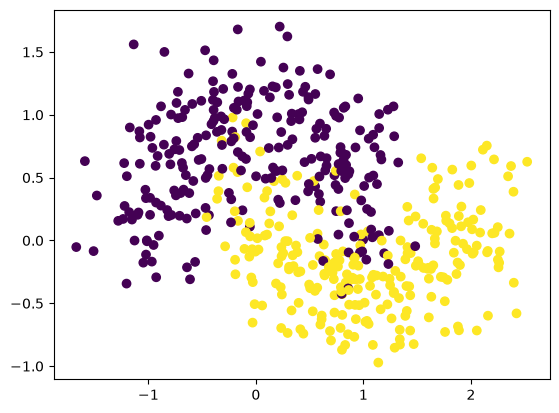

Predicted classes for k=3:


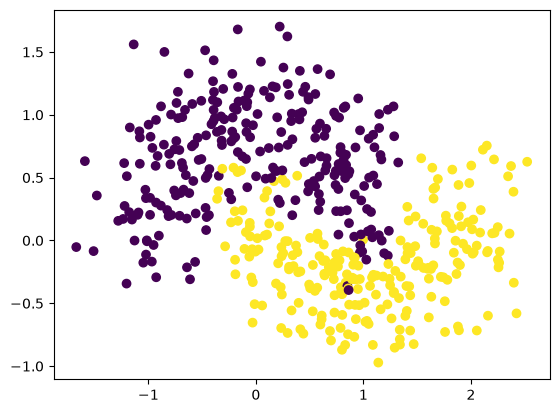

Predicted classes for k=10:


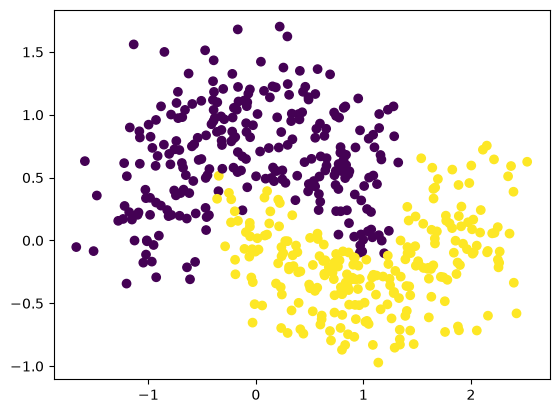

Predicted classes for k=50:


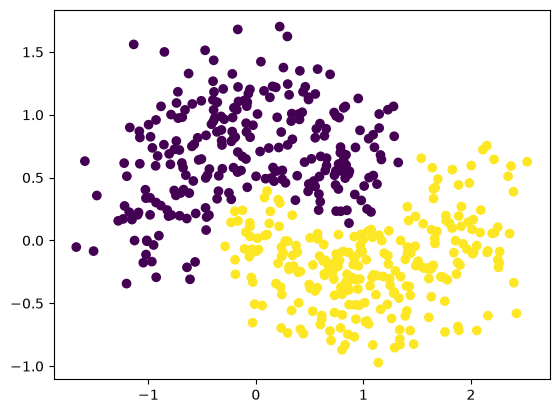

Predicted classes for k=100:


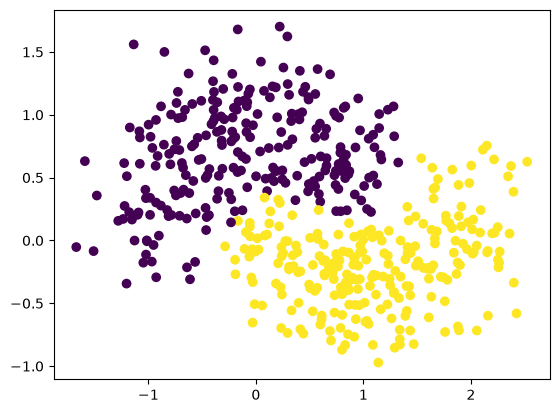

Predicted classes for k=300:


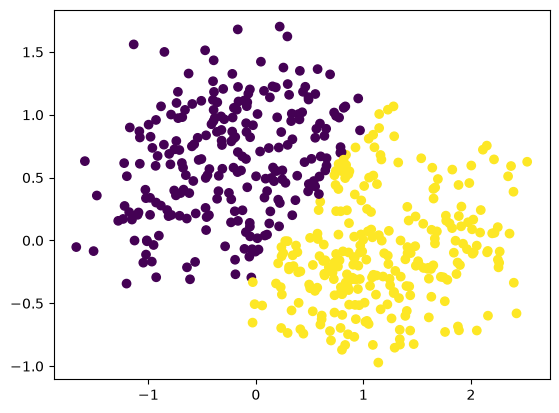

Predicted classes for k=499:


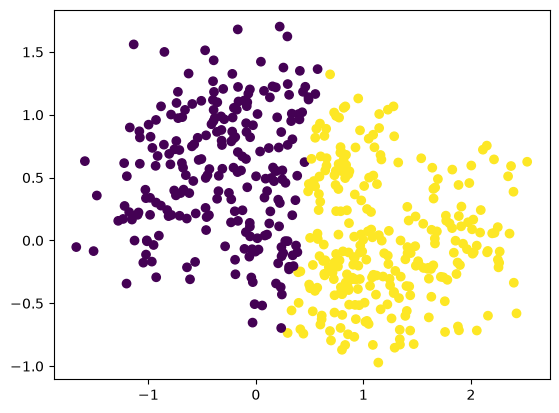

In [ ]:
X, y = make_moons(n_samples=500, noise=0.3)


for i in [1,10,100,300,499]:
    log_reg = KNN(k=i,task='classification')
    log_reg.fit(X,y)
    preds = log_reg.predict(X)
    print(f"Predicted classes for k={i}:")
    plt.scatter(X[:, 0], X[:, 1], c=preds)
    plt.show()


Prediction for k=1


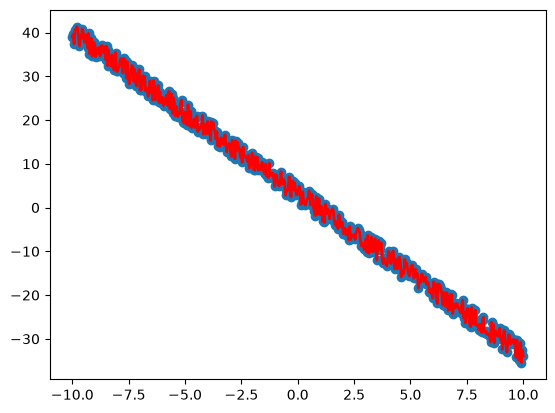

Prediction for k=3


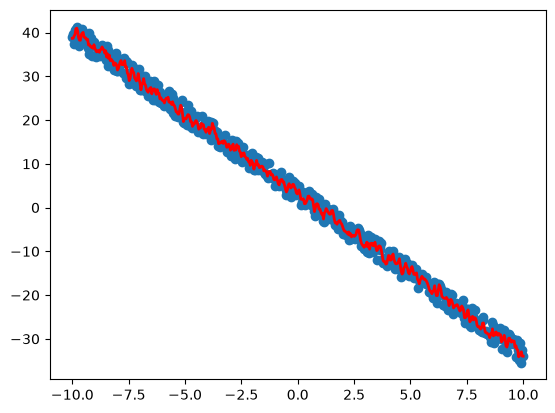

Prediction for k=10


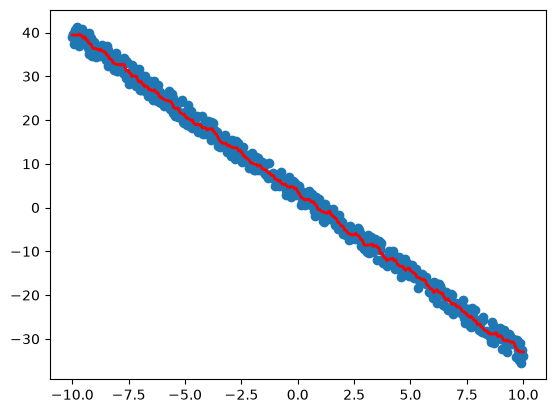

Prediction for k=50


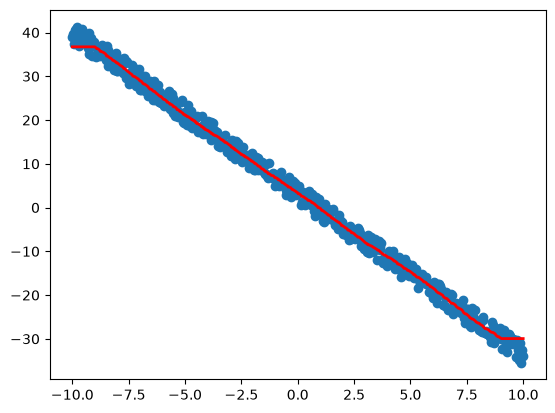

Prediction for k=100


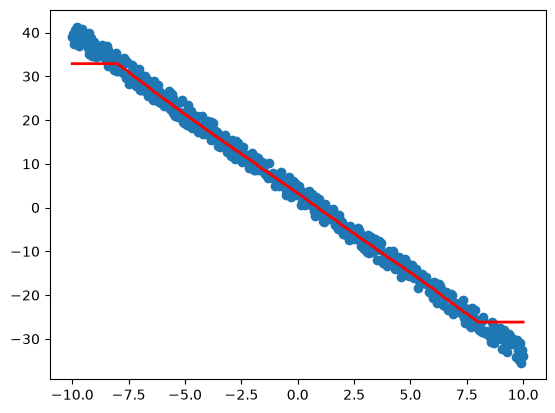

Prediction for k=300


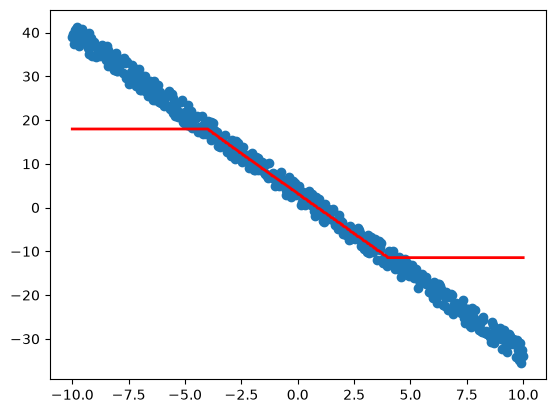

Prediction for k=499


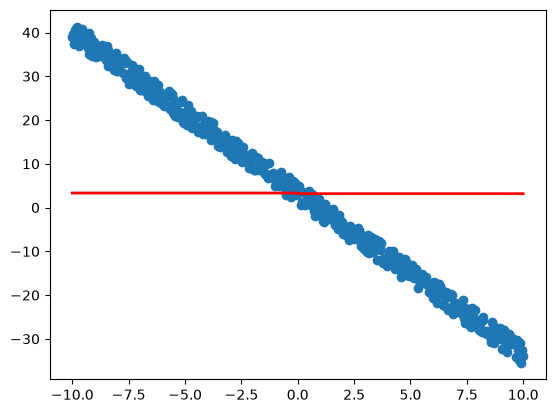

In [ ]:
def create_polinomial(power=1,noise=5,upper=10,lower=-10,num_points=500):
    x = np.linspace(lower,upper,num_points)

    y= np.random.rand(1)*2 + np.random.rand(num_points)*noise
    for i in range(power):
        y += x**(i+1) * np.random.randn(1)*2
    return x,y


x,y = create_polinomial()

for i in [1,3,10,100,300,499]:
    knn = KNN(k=i,task='regression')
    knn.fit(x.reshape(500,1),y)

    pred = knn.predict(x.reshape(500,1))
    print(f'Prediction for k={i}')
    plt.scatter(x,y)
    plt.plot(x, pred, color="red", linewidth=2, label=f"pred")
    plt.show()


### Overfit Example:

![bias](images/KNNOverfitExample.png)


### Training Curve Example:

![bias](images/KNNTrainingCurve.png)